In [66]:
import numpy as np
import matplotlib.pyplot as plt
import json


style = dict(
    marker="o",
    ms=4,
    linestyle="solid",
    linewidth=2,
    color="black"
)

In [67]:
class ThirdD:
    def __init__(self, poligons: list, rotations: list):
        self.p = poligons
        self.rota = rotations
        self.rotate()


    def rotate(self):
        r = self.p
        for pol in self.p:
            for p in pol:
                p = self.rot(p)

    def rot(self, p):
        for n in range(0,2):
            p = self.r(self.rota[n], n, p)
        return p

    def r(self, alfa: float, n: int, p: list):    
        if n >= 0 and n < 2:
            a = p[n-1]
            b = p[n+1]

        elif n == 2:
            a = p[1]
            b = p[0]
        else:
            return p
        
        na = a* np.cos(alfa) - b* np.sin(alfa)
        nb = a* np.sin(alfa) + b* np.cos(alfa)
        
        if n >= 0 and n < 2:
            p[n-1] = na
            p[n+1] = nb
        elif n == 2:
            p[1] = na
            p[0] = nb
        
        return p

    def poligons(self):
        for p in self.p:
            self.pol(p)

    def pol (self, p):
        pol = p
        x = []
        y = []
        for p in pol:
            self.x = 0
            self.y = 0
            self.xA(p[0])
            self.yA(p[1])
            self.zA(p[2])
            x.append(self.x)
            y.append(self.y)
        plt.plot(x,y,**style)
        plt.fill_between(x,y,color="orange")

    def xA(self,a):
        t = 3**0.5
        self.x += a*t/2 
        self.y -= a*0.5

    def yA(self,b):
        self.y += b

    def zA(self,c):
        t = 3**0.5
        self.x -= c*t/2
        self.y -= c*0.5


In [68]:
a = 15
b = 20
c = 10
pol = [
    [[0,0,0],
    [a,0,0],
    [a,b,0],
    [0,b,0],
    [0,0,0]],
    [[0,0,0],
    [0,b,0],
    [0,b,c],
    [0,0,c],
    [0,0,0]],
    [[0,0,0],
    [0,0,c],
    [a,0,c],
    [a,0,0],
    [0,0,0]],
    [[a,b,c],
    [a,0,c],
    [a,0,0],
    [a,b,0],
    [a,b,c]],
    [[a,b,c],
    [0,b,c],
    [0,b,0],
    [a,b,0],
    [a,b,c]],
    [[a,b,c],
    [a,0,c],
    [0,0,c],
    [0,b,c],
    [a,b,c]]
]

with open("3d.txt","w") as file:
    file.write(json.dumps(pol))

In [69]:
with open("3d.txt") as file:
    pol = json.loads(file.read())

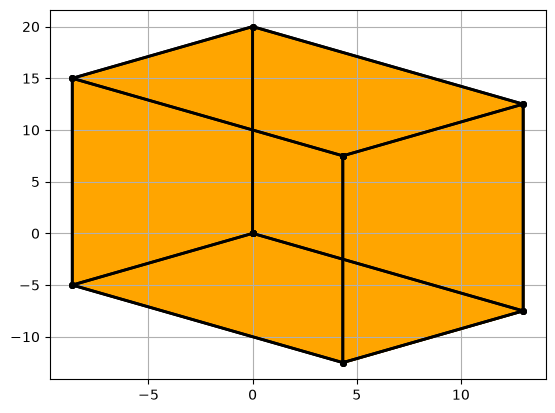

In [70]:
p = ThirdD(pol,[0,0,0])
p.poligons()
plt.grid(True)
plt.show()